In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned USGS dataset
df = pd.read_csv("../data/processed/usgs_inventory_missing_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (8981, 37)


,FireName,FireYear,FireIgnitionDate,FireState,AssessmentFireID,AssessmentSegmentID,UniqueObservationID,SiteName,ObservationDate,ObservationLatitude,...,1YearStormI30,1YearStormI60,RainfallRatio15,RainfallRatio30,RainfallRatio60,HM23,dNBR/1000,KF,UpstreamArea,PreviousUSGSInventory
0,Apple,2020,20200731,CA,aed2020,aed2020_7943,Apple_2020_0001,"""Dry Creek"" east of Little San Gorgonio Creek,...",20220819.0,34.052442,...,25.75,18.77,NaN,1.56,1.81,0.2670,0.2769,0.1200,1.2603,Graber (2023)
1,Apple,2020,20200731,CA,aed2020,aed2020_9918,Apple_2020_0002,Gilman Canyon (tributary to San Gorginio River...,20221129.0,34.031818,...,25.75,18.77,1.64,1.55,1.49,0.7365,0.5839,0.1279,7.5526,Graber (2023)
2,Bear,2021,20210608,UT,ber2021,ber2021_538,Bear_2021_0001,"US Hwy 6, MP 226.7, Crandall Canyon",20230903.0,39.763579,...,17.34,10.73,2.51,2.84,2.32,0.3714,0.4991,0.2720,10.8958,Graber (2024)
3,Blaisdell,2005,20050826,CA,bla,bla_122,Blaisdell_2005_0001,NaN,NaN,33.888020,...,15.49,11.20,0.34,0.39,0.48,0.0217,0.0695,0.0554,3.5557,Staley and others (2016)
4,Blaisdell,2005,20050826,CA,bla,bla_122,Blaisdell_2005_0002,NaN,NaN,33.888020,...,15.49,11.20,0.44,0.49,0.36,0.0217,0.0695,0.0554,3.5557,Staley and others (2016)


Response
0    7841
1    1140
Name: count, dtype: int64

Percentage distribution:
Response
0    87.306536
1    12.693464
Name: proportion, dtype: float64


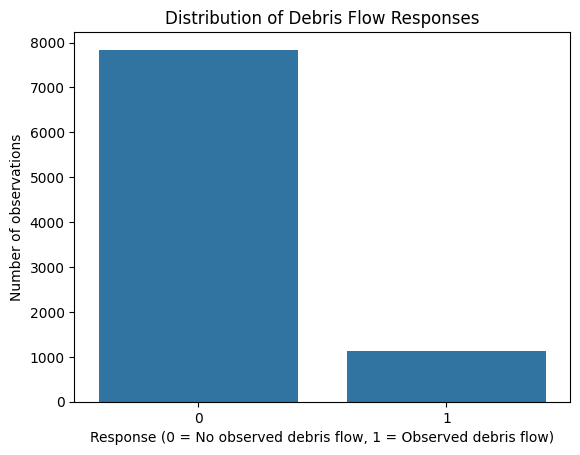

In [3]:
# Cell 5: Target variable distribution

print(df["Response"].value_counts())

print("\nPercentage distribution:")
print(df["Response"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="Response")
plt.title("Distribution of Debris Flow Responses")
plt.xlabel("Response (0 = No observed debris flow, 1 = Observed debris flow)")
plt.ylabel("Number of observations")
plt.show()


In [4]:
# Cell 10: Compare environmental features by debris-flow response

features = [
    "StormAccumulation",
    "StormDuration",
    "PeakI15",
    "PeakI30",
    "PeakI60",
    "RainfallRatio15",
    "RainfallRatio30",
    "RainfallRatio60",
    "HM23",
    "dNBR/1000",
    "KF",
    "UpstreamArea",
    "DaysSinceFire"
]

comparison = df.groupby("Response")[features].median().T

comparison.columns = [
    "No Observed Debris Flow (0)",
    "Observed Debris Flow (1)"
]

comparison["Difference"] = (
    comparison["Observed Debris Flow (1)"]
    - comparison["No Observed Debris Flow (0)"]
)

comparison

,No Observed Debris Flow (0),Observed Debris Flow (1),Difference
StormAccumulation,6.9000,49.3000,42.4000
StormDuration,6.1000,8.0000,1.9000
PeakI15,13.0000,43.8500,30.8500
PeakI30,9.0000,31.0000,22.0000
PeakI60,5.8000,22.9000,17.1000
RainfallRatio15,0.3900,1.0800,0.6900
RainfallRatio30,0.4000,1.2200,0.8200
RainfallRatio60,0.3900,1.2200,0.8300
HM23,0.3457,0.5153,0.1696
dNBR/1000,0.4435,0.4491,0.0056


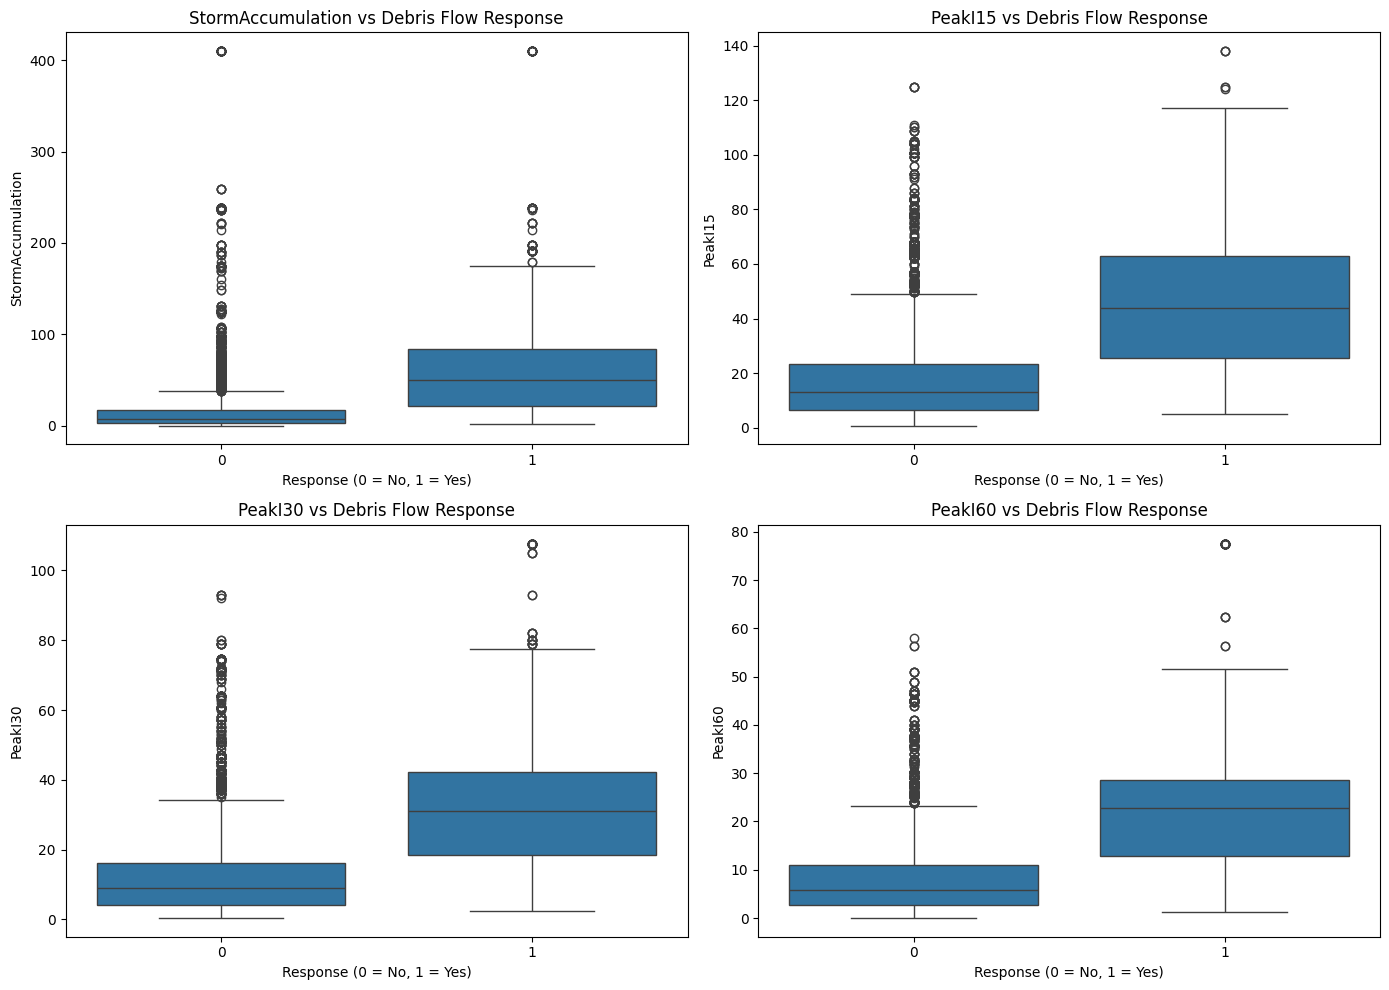

In [5]:
# Cell 11: Rainfall feature comparison

rainfall_features = [
    "StormAccumulation",
    "PeakI15",
    "PeakI30",
    "PeakI60"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(rainfall_features, axes.flatten()):

    sns.boxplot(
        data=df,
        x="Response",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} vs Debris Flow Response")
    ax.set_xlabel("Response (0 = No, 1 = Yes)")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


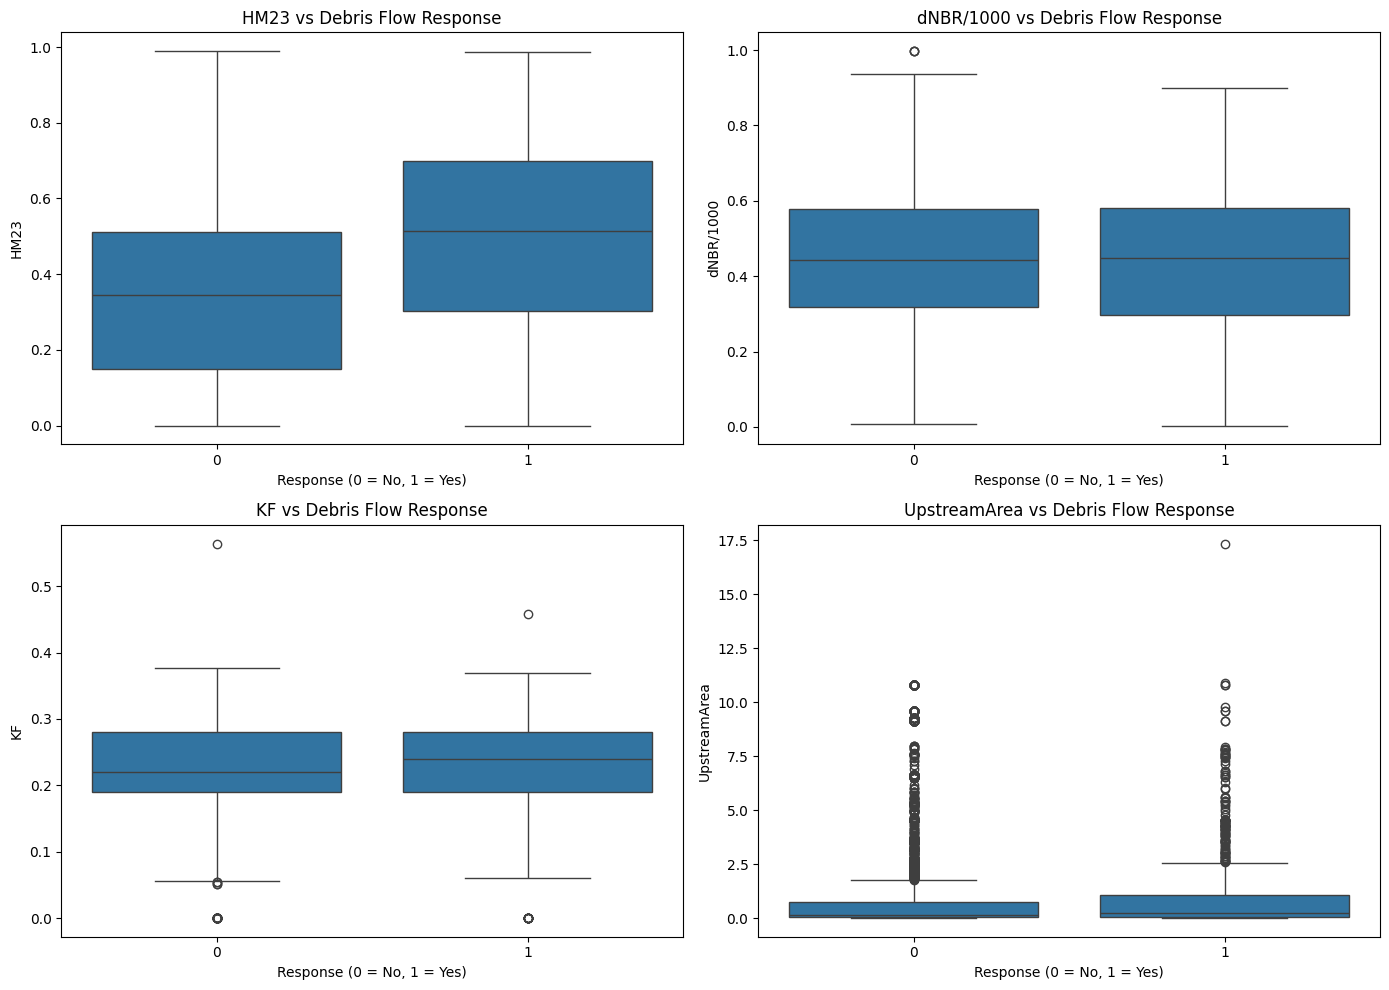

In [6]:
# Cell 12: Environmental feature comparison

environment_features = [
    "HM23",
    "dNBR/1000",
    "KF",
    "UpstreamArea"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(environment_features, axes.flatten()):

    sns.boxplot(
        data=df,
        x="Response",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} vs Debris Flow Response")
    ax.set_xlabel("Response (0 = No, 1 = Yes)")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

In [7]:
# Cell 13: Missing-value percentage by response

selected_features = [
    "StormAccumulation",
    "StormDuration",
    "PeakI15",
    "PeakI30",
    "PeakI60",
    "HM23",
    "dNBR/1000",
    "KF",
    "UpstreamArea"
]

missing_by_response = (
    df.groupby("Response")[selected_features]
    .apply(lambda group: group.isnull().mean() * 100)
    .T
)

missing_by_response.columns = [
    "Response 0 Missing %",
    "Response 1 Missing %"
]

missing_by_response


,Response 0 Missing %,Response 1 Missing %
StormAccumulation,19.028185,15.701754
StormDuration,24.371891,22.719298
PeakI15,11.988267,8.421053
PeakI30,11.592909,8.859649
PeakI60,11.172044,0.526316
HM23,4.030098,11.578947
dNBR/1000,4.030098,11.578947
KF,4.030098,11.578947
UpstreamArea,4.030098,11.578947


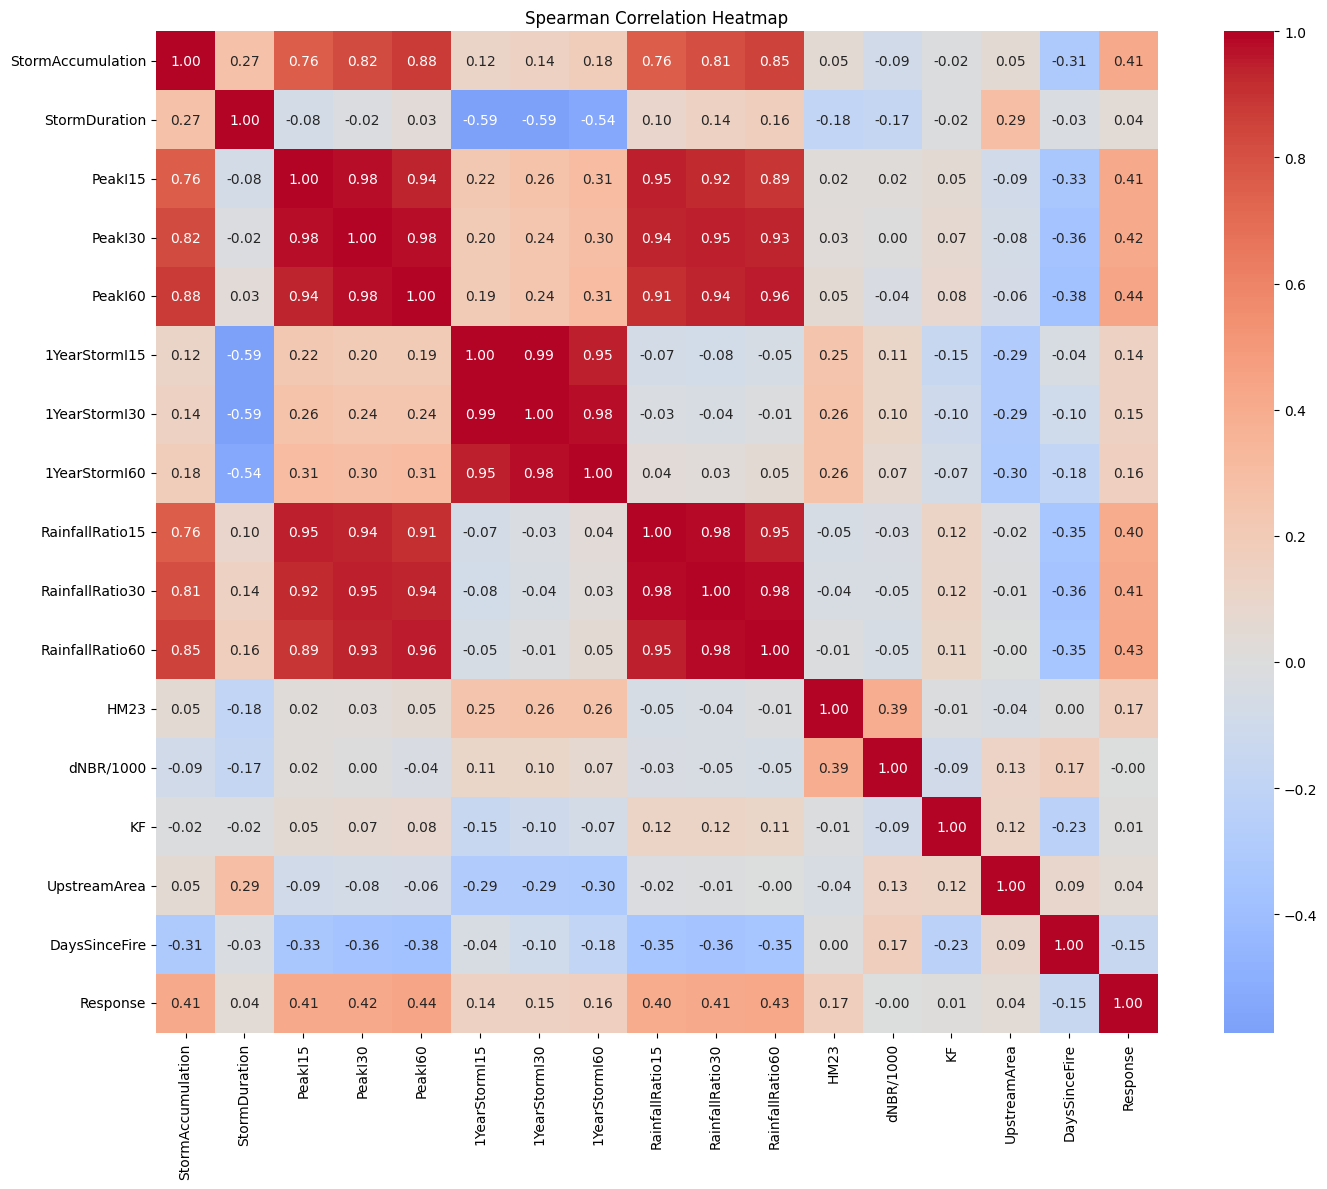

In [8]:
# Cell 14: Spearman correlation analysis

correlation_features = [
    "StormAccumulation",
    "StormDuration",
    "PeakI15",
    "PeakI30",
    "PeakI60",
    "1YearStormI15",
    "1YearStormI30",
    "1YearStormI60",
    "RainfallRatio15",
    "RainfallRatio30",
    "RainfallRatio60",
    "HM23",
    "dNBR/1000",
    "KF",
    "UpstreamArea",
    "DaysSinceFire",
    "Response"
]

corr = df[correlation_features].corr(method="spearman")

plt.figure(figsize=(15, 12))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

In [9]:
# Cell 15: Number of observations per wildfire

fire_summary = (
    df.groupby("FireName")
    .agg(
        Total_Observations=("Response", "size"),
        Positive_Responses=("Response", "sum"),
        Unique_Classes=("Response", "nunique")
    )
)

fire_summary["Positive_Percentage"] = (
    fire_summary["Positive_Responses"]
    / fire_summary["Total_Observations"] * 100
)

print("Number of wildfire areas:", len(fire_summary))

print("\nWildfires with both response classes:")
print((fire_summary["Unique_Classes"] == 2).sum())

print("\nWildfires with only one response class:")
print((fire_summary["Unique_Classes"] == 1).sum())

fire_summary.sort_values(
    by="Total_Observations",
    ascending=False
).head(15)

Number of wildfire areas: 80

Wildfires with both response classes:
52

Wildfires with only one response class:
28


,Total_Observations,Positive_Responses,Unique_Classes,Positive_Percentage
FireName,,,,
Grizzly Creek,2450,50,2,2.040816
Thomas,857,171,2,19.953326
Buzzard,679,26,2,3.829161
Tadpole,648,16,2,2.469136
Pinal,525,14,2,2.666667
Station,489,108,2,22.085890
Ferguson,366,28,2,7.650273
Coal Seam,253,17,2,6.719368
Fish (San Gabriel Complex),241,7,2,2.904564


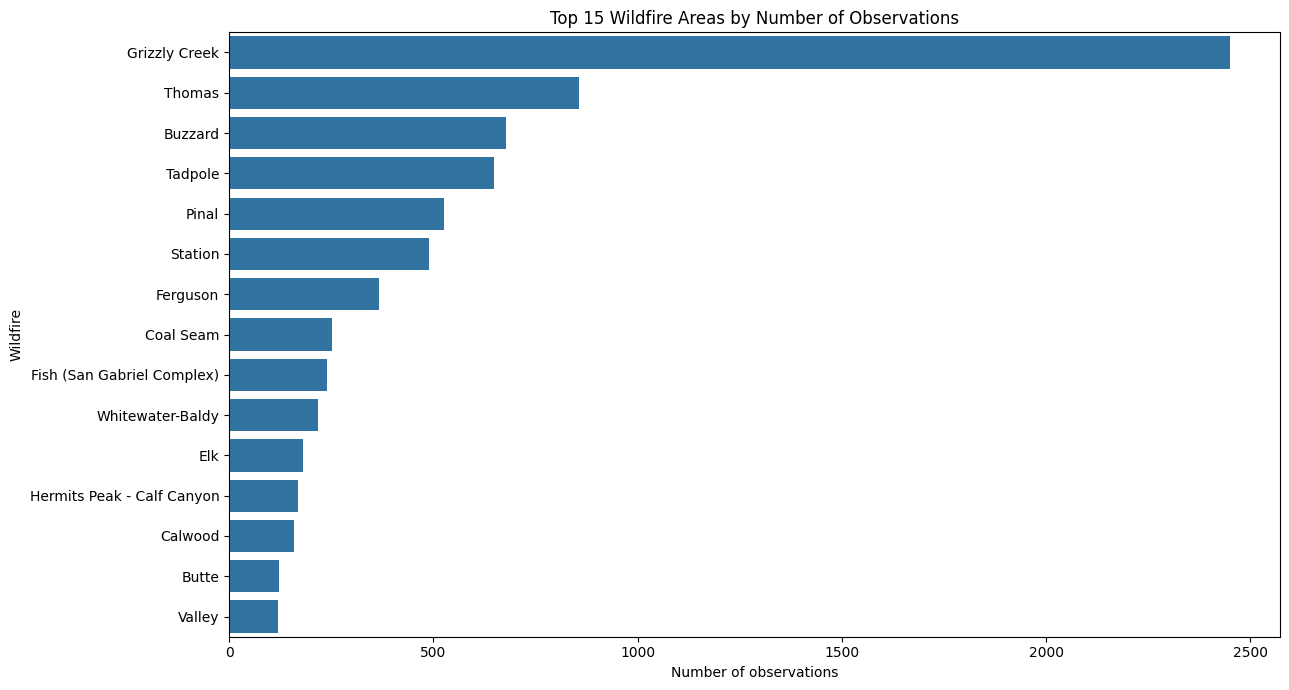

In [10]:
# Cell 16: Largest wildfire groups

top_fires = (
    df["FireName"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    x=top_fires.values,
    y=top_fires.index
)

plt.title("Top 15 Wildfire Areas by Number of Observations")
plt.xlabel("Number of observations")
plt.ylabel("Wildfire")

plt.tight_layout()
plt.show()


In [11]:
# Cell 17: Check wildfire grouping identifiers

print("Unique FireName values:", df["FireName"].nunique())

print("Missing FireName values:", df["FireName"].isna().sum())

print("Missing AssessmentFireID values:",
      df["AssessmentFireID"].isna().sum())

print("\nFireName to AssessmentFireID mapping:")
print(
    df.groupby("FireName")["AssessmentFireID"]
    .nunique(dropna=True)
    .sort_values(ascending=False)
    .head(10)
)

Unique FireName values: 80
Missing FireName values: 0
Missing AssessmentFireID values: 2

FireName to AssessmentFireID mapping:
FireName
Apple                    1
Bear                     1
Blaisdell                1
Bond                     1
Boot                     1
Briceburg                1
Buckweed                 1
Butte                    1
Buzzard                  1
CZU Lightning Complex    1
Name: AssessmentFireID, dtype: int64


In [12]:

# Cell 17: Find highly correlated numerical features

numeric_features = [
    "StormAccumulation",
    "StormDuration",
    "PeakI15",
    "PeakI30",
    "PeakI60",
    "1YearStormI15",
    "1YearStormI30",
    "1YearStormI60",
    "RainfallRatio15",
    "RainfallRatio30",
    "RainfallRatio60",
    "HM23",
    "dNBR/1000",
    "KF",
    "UpstreamArea",
    "DaysSinceFire"
]

corr_matrix = df[numeric_features].corr(method="spearman")

# Extract only unique feature pairs
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_correlations = (
    upper_triangle.stack()
    .reset_index()
)

high_correlations.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

high_correlations["Absolute_Correlation"] = (
    high_correlations["Correlation"].abs()
)

high_correlations = high_correlations[
    high_correlations["Absolute_Correlation"] >= 0.80
].sort_values(
    by="Absolute_Correlation",
    ascending=False
)

high_correlations


,Feature_1,Feature_2,Correlation,Absolute_Correlation
86,1YearStormI15,1YearStormI30,0.987929,0.987929
154,RainfallRatio30,RainfallRatio60,0.982846,0.982846
137,RainfallRatio15,RainfallRatio30,0.981870,0.981870
35,PeakI15,PeakI30,0.979391,0.979391
52,PeakI30,PeakI60,0.978118,0.978118
103,1YearStormI30,1YearStormI60,0.977480,0.977480
74,PeakI60,RainfallRatio60,0.956007,0.956007
57,PeakI30,RainfallRatio30,0.950294,0.950294
87,1YearStormI15,1YearStormI60,0.950012,0.950012
138,RainfallRatio15,RainfallRatio60,0.947269,0.947269


In [13]:
# Cell 18: Feature association with target

target_correlations = (
    df[numeric_features + ["Response"]]
    .corr(method="spearman")["Response"]
    .drop("Response")
    .sort_values(key=abs, ascending=False)
)

print("Spearman correlation with Response:")
print(target_correlations)

Spearman correlation with Response:
PeakI60              0.441303
RainfallRatio60      0.426921
PeakI30              0.422723
StormAccumulation    0.414647
PeakI15              0.413528
RainfallRatio30      0.411369
RainfallRatio15      0.403727
HM23                 0.170945
1YearStormI60        0.161867
DaysSinceFire       -0.152230
1YearStormI30        0.148540
1YearStormI15        0.137310
UpstreamArea         0.042140
StormDuration        0.039478
KF                   0.011075
dNBR/1000           -0.002997
Name: Response, dtype: float64
